In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
plot_dir = '/n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/double_cascade_identification/plots/'
results_dir = '/n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/double_cascade_identification/training_output/new_MC/deepcore_cut/dynedge_dbang_decay_length/'


In [33]:
fifty_epoch_results = pd.read_csv(results_dir + "results_with_energy_cut_even_longer_training.csv")
val_results = pd.read_csv(results_dir + "validation_set_continued_training.csv")

# background_results = pd.read_csv(results_dir + "neutrino_background_checks.csv")
background_results = pd.read_csv(results_dir + "100_epoch_background_checks.csv")
hnl_verification_results = pd.read_csv(results_dir + "100_epoch_hnl_verification_checks.csv")

In [34]:
hnl_verification_results.keys()
# It looks like the test and validation sets are the same anyway, so let's not sweat this for now

Index(['Unnamed: 0', 'dbang_decay_length_pred', 'dbang_decay_length', 'pid',
       'energy', 'event_weight', 'azimuth', 'zenith', 'position_x',
       'position_y', 'position_z', 'elasticity', 'interaction_type',
       'inelasticity', 'event_no'],
      dtype='object')

Text(0, 0.5, 'simulated signal events')

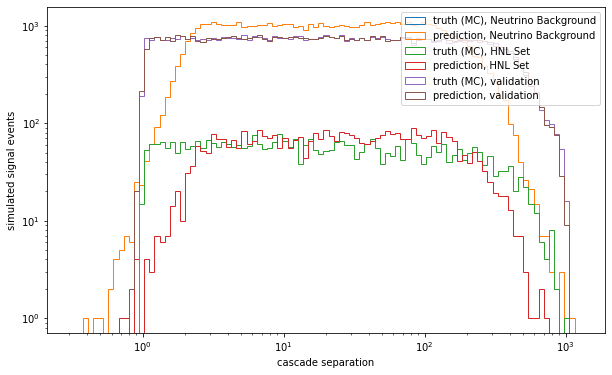

In [35]:
plt.figure(figsize=(10, 6))
bins = np.logspace(-0.5, 3.1, 100)

plt.hist(background_results['dbang_decay_length'], histtype="step", bins=bins, label="truth (MC), Neutrino Background")
plt.hist(background_results['dbang_decay_length_pred'], histtype="step", bins=bins, label="prediction, Neutrino Background")

plt.hist(hnl_verification_results['dbang_decay_length'], histtype="step", bins=bins, label="truth (MC), HNL Set")
plt.hist(hnl_verification_results['dbang_decay_length_pred'], histtype="step", bins=bins, label="prediction, HNL Set")

plt.hist(val_results['dbang_decay_length'], histtype="step", bins=bins, label="truth (MC), validation")
plt.hist(val_results['dbang_decay_length_pred'], histtype="step", bins=bins, label="prediction, validation")

# plt.hist(fifty_epoch_results['dbang_decay_length'], histtype="step", bins=bins, label="truth (MC), 100 epochs")
# plt.hist(fifty_epoch_results['dbang_decay_length_pred'], histtype="step", bins=bins, label="prediction, 100 epochs")


plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.xlabel('cascade separation')
plt.ylabel('simulated signal events')

In [15]:
background_results['dbang_decay_length']

0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
59408    0.0
59409    0.0
59410    0.0
59411    0.0
59412    0.0
Name: dbang_decay_length, Length: 59413, dtype: float64

Text(0.5, 1.0, 'Cascade separation, HNL verification sample')

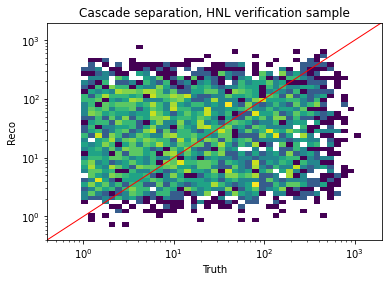

In [36]:
from matplotlib import colors

bins = np.logspace(-0.4, 3.3, 50)
plt.hist2d(hnl_verification_results['dbang_decay_length'],hnl_verification_results['dbang_decay_length_pred'], bins=bins, norm=colors.LogNorm())
# Add a line 
plt.plot([-2, 2000], [-2, 2000], color='red', linestyle='-', linewidth=1)

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Truth")
plt.ylabel("Reco")
plt.title("Cascade separation, HNL verification sample")


Text(0.5, 1.0, 'Cascade separation, HNL only, 100 epochs')

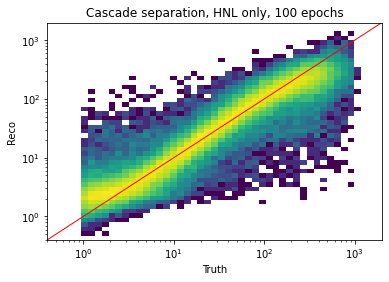

In [6]:
from matplotlib import colors

bins = np.logspace(-0.4, 3.3, 50)
plt.hist2d(longer_results['dbang_decay_length'],longer_results['dbang_decay_length_pred'], bins=bins, norm=colors.LogNorm())
# Add a line 
plt.plot([-2, 2000], [-2, 2000], color='red', linestyle='-', linewidth=1)

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Truth")
plt.ylabel("Reco")
plt.title("Cascade separation, HNL only, 100 epochs")


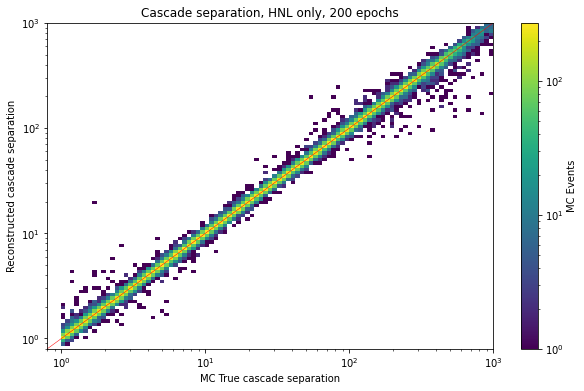

In [17]:
plt.figure(figsize=(10, 6))
bins = np.logspace(-0.1, 3, 100)

mask = val_results['event_weight']> 0

h = plt.hist2d(
    val_results[mask]['dbang_decay_length'],
    val_results[mask]['dbang_decay_length_pred'],
#     weights=val_results[mask]['event_weight'], 
    bins=bins, 
    norm=colors.LogNorm(),
)

# Add a line 
plt.plot([-2, 2000], [-2, 2000], color='red', linestyle='-', linewidth=0.5)

plt.xscale('log')
plt.yscale('log')

plt.xlabel("MC True cascade separation")
plt.ylabel("Reconstructed cascade separation")
plt.title("Cascade separation, HNL only, 200 epochs")
# Add colorbar
plt.colorbar(h[3], label='MC Events')
figname = plot_dir + 'validation_sample_cascade_separation.pdf'
plt.savefig(figname, dpi=300)

In [16]:
figname = plot_dir + 'validation_sample_cascade_separation.pdf'
plt.savefig(figname, dpi=300)

<Figure size 432x288 with 0 Axes>

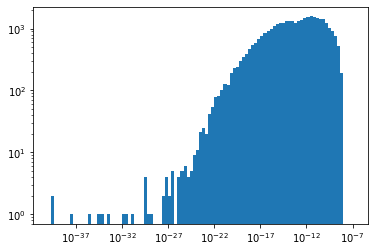

In [41]:
mask = val_results['event_weight']> 0

plt.hist(val_results[mask]['event_weight'], bins = np.logspace(-40, -7, 100))
plt.xscale('log')
plt.yscale('log')

In [42]:
print(len(val_results['event_weight']))
print(len(val_results[mask]['event_weight']))

54533
36145


Text(0.5, 1.0, 'Cascade separation, HNL only, 100 more epochs, Test Set')

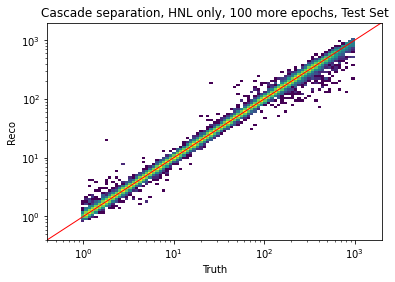

In [17]:
bins = np.logspace(-0.4, 3.3, 100)
plt.hist2d(val_results['dbang_decay_length'],val_results['dbang_decay_length_pred'], bins=bins, norm=colors.LogNorm())
# Add a line 
plt.plot([-2, 2000], [-2, 2000], color='red', linestyle='-', linewidth=1)

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Truth")
plt.ylabel("Reco")
plt.title("Cascade separation, HNL only, 100 more epochs, Test Set")

In [18]:
residual = (val_results['dbang_decay_length_pred'] - val_results['dbang_decay_length'])/val_results['dbang_decay_length']

val_results.keys()

Index(['Unnamed: 0', 'dbang_decay_length_pred', 'dbang_decay_length', 'pid',
       'energy', 'event_weight', 'azimuth', 'zenith', 'position_x',
       'position_y', 'position_z', 'elasticity', 'interaction_type',
       'inelasticity', 'event_no'],
      dtype='object')

Text(0.5, 1.0, 'Cascade separation, HNL only, 100 more epochs')

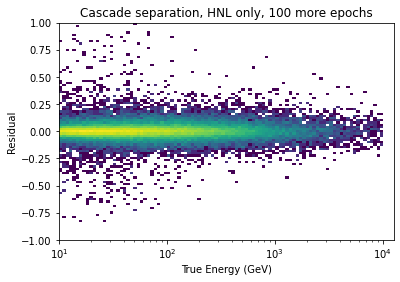

In [19]:
x_bins = np.logspace(1, 4.1, 100)
y_bins = np.linspace(-1, 1, 100)
plt.hist2d(val_results['energy'],residual, bins=[x_bins, y_bins], norm=colors.LogNorm())
# Add a line 
plt.plot([-2, 2000], [-2, 2000], color='red', linestyle='-', linewidth=1)

plt.xscale('log')
# plt.yscale('log')

plt.xlabel("True Energy (GeV)")
plt.ylabel("Residual")
plt.title("Cascade separation, HNL only, 100 more epochs")

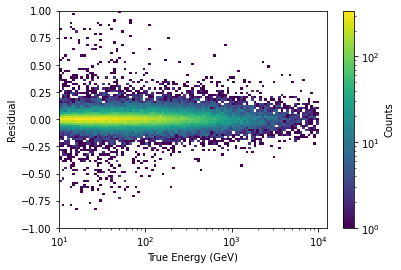

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors

x_bins = np.logspace(1, 4.1, 100)
y_bins = np.linspace(-1, 1, 100)

# Create 2D histogram and store the returned object
h = plt.hist2d(val_results['energy'], residual, bins=[x_bins, y_bins], norm=colors.LogNorm())

# Add a diagonal line (adjusted to your axis ranges if needed)
# plt.plot([10, 12500], [-2, 2000], color='red', linestyle='-', linewidth=1)

plt.xscale('log')
# plt.yscale('log')

plt.xlabel("True Energy (GeV)")
plt.ylabel("Residual")

# Add colorbar
plt.colorbar(h[3], label='Counts')

plt.show()
